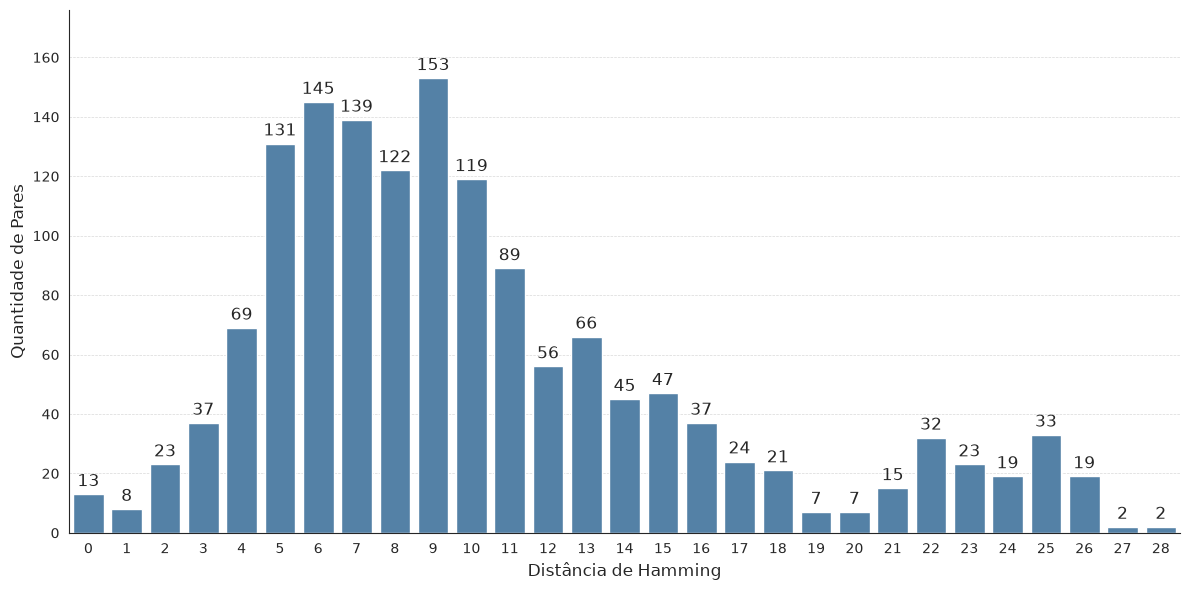

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Carregamento e Preparação dos Dados
# ---------------------------------------------------------
file_path = 'data/prova_cn.csv'
df = pd.read_csv(file_path)

# Isolamento das colunas de questões (excluindo metadados)
metadata_cols = {'estudante', 'datetime', 'carimbo_entrega', 'pontuacao', 'serie_turma', 'materia'}
question_cols = [col for col in df.columns if col not in metadata_cols]

# ---------------------------------------------------------
# 2. Cálculo da Distância e Similaridade de Hamming
# ---------------------------------------------------------
def hamming_distance(respostas_a, respostas_b):
    """Calcula a quantidade de respostas divergentes entre dois estudantes."""
    return np.sum(respostas_a != respostas_b)

def processar_pares_intra_turma(data, q_cols):
    """Processa a distância e similaridade de Hamming apenas entre estudantes da mesma turma."""
    pairs = []

    for turma, grupo in data.groupby('serie_turma'):
        estudantes = grupo['estudante'].values
        respostas = grupo[q_cols].values
        n = len(estudantes)

        if n < 2:
            continue

        # Combinação triangular (i < j) para evitar duplicações e auto-comparações
        for i in range(n):
            for j in range(i + 1, n):
                dist_h = hamming_distance(respostas[i], respostas[j])
                sim_h = 1.0 - (dist_h / len(q_cols))
                pairs.append({
                    'serie_turma': turma,
                    'estudante_1': estudantes[i],
                    'estudante_2': estudantes[j],
                    'hamming_distance': dist_h,
                    'hamming_similarity': sim_h
                })

    return pd.DataFrame(pairs)

# Execução da análise intra-turma
df_pairs = processar_pares_intra_turma(df, question_cols)

# ---------------------------------------------------------
# 3. Consolidação para o Gráfico Único (Distância x Quantidade de Pares)
# ---------------------------------------------------------
df_dist_counts = df_pairs.groupby('hamming_distance', observed=False).size().reset_index(name='quantidade_pares')

# ---------------------------------------------------------
# 4. Renderização do Gráfico (Distância de Hamming vs Quantidade de Pares)
# ---------------------------------------------------------
sns.set_style("white")

fig, ax = plt.subplots(figsize=(12, 6), facecolor='white')
ax.set_facecolor('white')

sns.barplot(
    data=df_dist_counts,
    x='hamming_distance',
    y='quantidade_pares',
    color='#4682b4',
    ax=ax
)

plt.title('', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Distância de Hamming', fontsize=12)
plt.ylabel('Quantidade de Pares', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.3, color='gray')
plt.ylim(0, df_dist_counts['quantidade_pares'].max() * 1.15)

# Anotações numéricas legíveis sobre cada barra
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=12,
            xytext=(0, 3),
            textcoords='offset points'
        )

sns.despine()
plt.tight_layout()
plt.show()


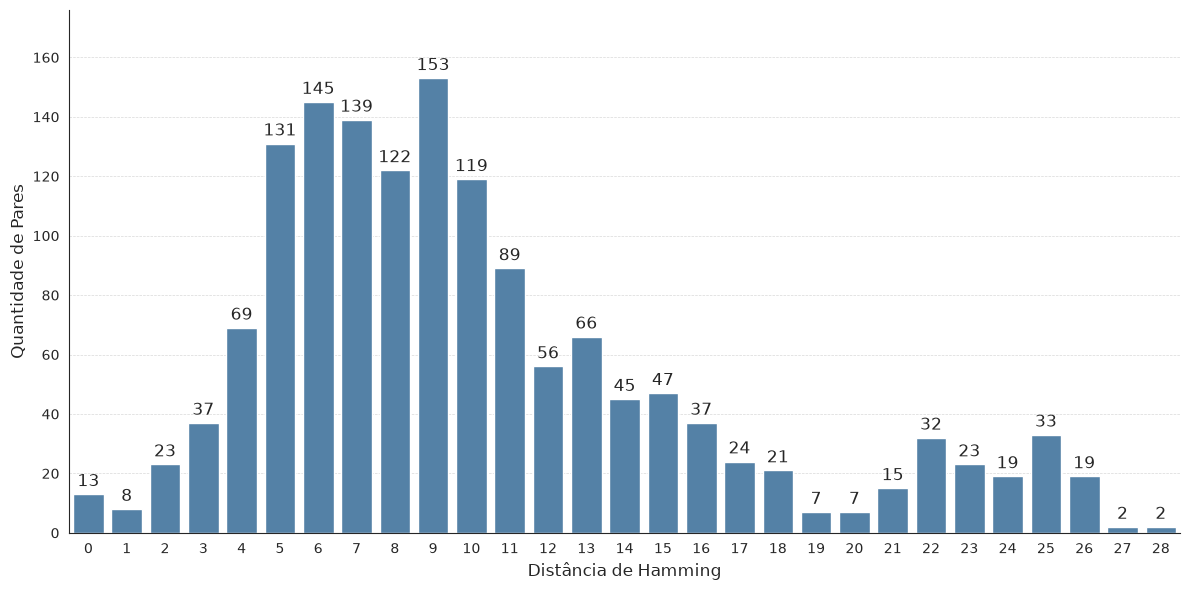

In [5]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Carregamento dos Dados e Mapeamento de Colunas
# ---------------------------------------------------------
file_path = 'data/prova_cn.csv' if os.path.exists('data/prova_cn.csv') else 'prova_cn.csv'
df = pd.read_csv(file_path)

# Identificação das colunas das questões (excluindo metadados)
metadata_cols = {'estudante', 'datetime', 'carimbo_entrega', 'pontuacao', 'serie_turma', 'materia'}
question_cols = [col for col in df.columns if col not in metadata_cols]

# ---------------------------------------------------------
# 2. Funções de Distância de Hamming e Processamento Intra-Turma
# ---------------------------------------------------------
def hamming_distance(respostas_a, respostas_b):
    """Calcula a quantidade absoluta de respostas divergentes entre dois vetores."""
    return np.sum(respostas_a != respostas_b)

def processar_distancia_intra_turma(data, q_cols):
    """Calcula a distância de Hamming exclusivamente entre estudantes da mesma turma."""
    pairs = []

    for turma, grupo in data.groupby('serie_turma'):
        estudantes = grupo['estudante'].values
        respostas = grupo[q_cols].values
        n = len(estudantes)

        if n < 2:
            continue

        # Combinação triangular para evitar auto-comparações e redundâncias
        for i in range(n):
            for j in range(i + 1, n):
                dist_h = hamming_distance(respostas[i], respostas[j])
                sim_h = 1.0 - (dist_h / len(q_cols))
                pairs.append({
                    'serie_turma': turma,
                    'estudante_1': estudantes[i],
                    'estudante_2': estudantes[j],
                    'hamming_distance': dist_h,
                    'hamming_similarity': sim_h
                })

    return pd.DataFrame(pairs)

# Execução do cálculo de distância
df_pairs = processar_distancia_intra_turma(df, question_cols)

# Consolidação da contagem por Distância de Hamming
df_dist_counts = df_pairs.groupby('hamming_distance', observed=False).size().reset_index(name='quantidade_pares')

# ---------------------------------------------------------
# 3. Renderização do Gráfico (Distância de Hamming vs Quantidade de Pares)
# ---------------------------------------------------------
sns.set_style("white")

fig, ax = plt.subplots(figsize=(12, 6), facecolor='white')
ax.set_facecolor('white')

sns.barplot(
    data=df_dist_counts,
    x='hamming_distance',
    y='quantidade_pares',
    color='#4682b4',
    ax=ax
)

plt.xlabel('Distância de Hamming', fontsize=12)
plt.ylabel('Quantidade de Pares', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3, color='gray')
plt.ylim(0, df_dist_counts['quantidade_pares'].max() * 1.15)

# Rótulos numéricos acima de cada barra
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            fontsize=12,
            xytext=(0, 3),
            textcoords='offset points'
        )

sns.despine()
plt.tight_layout()
plt.show()